# Grafted neuron morphology, 2WPT — regular CZI images (no Airyscan processing)

**Question:** do grafted **bmi1** neurons differ in morphology from **scr** neurons? The researcher asked
for any shape difference, in particular the diameter of the extensions.

**Data (`2WPT/`):**
- Two mice. **ID06902** has both scr and bmi1. **ID06914** has scr only and is used as a second-mouse
  reference.
- This notebook uses **only the regular CZI files (no `Airyscan Processing` in the name), max-projected over Z**.
  The Airyscan-processed files are analysed separately in
  `morphology_2WPT_airyscan.ipynb`.
- **Neurons:** the `AF594-T1` channel. `DAPI` is the nuclear stain. `AF405`, where present, is a
  diffuse tissue signal, not nuclei. Channels are picked **by name**, because their order changes
  between files.
- **Pixel sizes:** 35.3, 54.8 and 70.6 nm, from 63x and 40x objectives. Every image is resampled to
  70.6 nm, so all measurements are in µm.

**Pipeline** (`morphology_utils.py`, shared by both notebooks):
1. **Background:** subtract a large Gaussian (σ = 5 µm) and divide by robust noise, giving an SNR image.
2. **AF594 mask:** the FAST U-Net++ filament mask (pretrained, also used for the axon breaks) united
   with SNR > 3. A piece is kept only if it contains clearly bright signal (SNR > 6).
3. **Cell bodies:** Cellpose-SAM at 0.12 µm/px. Keep objects of 30–900 µm² with solidity ≥ 0.85 and
   positive AF594 signal.
4. **Extensions:** the mask minus cell bodies, skeletonized; end branches < 2 µm are pruned. Each
   branch gets its length and tortuosity (path length / straight distance).
5. **Extension diameter:** the **FWHM of the intensity profile across the branch**, measured every
   0.5 µm. This is threshold-free, so a brightness difference between conditions does not change the
   width. Per branch: the median width and its CV along the branch (high CV = beaded / varicose).
6. **Per cell body:** area, max length, circularity, aspect ratio, number of primary extensions
   (AF594 pieces crossing a 1–3 µm ring), and primary-extension diameter (widths 1–5 µm from the soma).
7. **Dense clusters vs isolated neurons:** many bmi1 fields show a dense graft core, a mesh of packed
   cells and overlapping processes. There, skeleton crossings count as branch points and packed
   membranes measure as thick extensions. Each point gets the local AF594 mask fraction in a 20 µm
   window; above 0.20 counts as a dense cluster. The **isolated-extension metrics** use only points
   below that, which is the fair comparison of single extensions. The share of extensions in dense
   clusters is reported as its own measure.
8. **Swellings**, matching Flamier et al. 2018, Fig 3F (% of axons with ≥ 1 swelling). A swelling is a
   run of width samples that meets all of these:
   - wider than 2× the branch's median width, and at least 0.3 µm wider;
   - brighter than 1.2× the branch's median peak intensity;
   - wider than the samples just outside it;
   - at least 2 µm from either branch end, so junction blobs are not counted.

   Reported as % of branches (≥ 3 µm) with at least one swelling, and as swellings per 100 µm.
9. **Isolated neurons** (Flamier et al. 2018, Fig 2B): a cell body counts as isolated when the
   AF594 mask covers < 8.5% of a 1–20 µm ring around it and no other cell body lies within 10 µm.
   The threshold was calibrated by eye: clearly isolated neurons 5–8%, cells in graft cores mostly
   9–29%. The margin is thin, so check the gallery of all isolated neurons. Each AF594 mask pixel goes to the
   nearest cell body along the mask, with gaps ≤ 1 µm bridged. Per neuron:
   - **dendrite length**;
   - **dendrite surface area**, π × mean FWHM diameter × length, which is what IMARIS reports as
     "dendrite area" (the paper's ~6,500 µm² for ~2,300 µm of dendrite implies ~0.9 µm diameter);
   - **dendritic field area**, the convex hull of the arbor;
   - **branch points and tips**.

**Statistics:** one value per image, or per cell body for soma metrics. The main test is a
Mann-Whitney test of **bmi1 vs scr within mouse ID06902**, the only mouse with both conditions. The
scr ID06902 vs scr ID06914 test shows how much two mice differ in the same condition.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, '/Users/ctuna/Desktop/axon_codes/results_2WPT')
import importlib, morphology_utils as mu
importlib.reload(mu)

AIRYSCAN = False
DATA_DIR = '/Users/ctuna/Desktop/axon_codes/2WPT'
OUT_DIR  = '/Users/ctuna/Desktop/axon_codes/results_2WPT/czi'
CSV_DIR, FIG_DIR = os.path.join(OUT_DIR, 'csv'), os.path.join(OUT_DIR, 'figures')
os.makedirs(CSV_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option('display.width', 200)

## Files and channels

In [2]:
files = mu.list_images(DATA_DIR, airyscan=AIRYSCAN)
print(len(files), 'images')
display(files.groupby(['mouse', 'condition']).agg(n=('filename', 'size'),
        pixel_nm=('px_nm', lambda s: sorted(set(s))), objective=('objective', lambda s: sorted(set(s))),
        z_planes=('n_z', lambda s: f'{s.min()}–{s.max()}')))
display(files.groupby(['mouse', 'condition'])['channels'].value_counts().rename('n').to_frame())

72 images


n            pixel_nm                          objective z_planes
mouse   condition                                                                    
ID06902 bmi1       33        [35.3, 70.6]  [C 63x/1.40, Plan-Apochromat M27]     1–21
        scr        21              [35.3]                       [C 63x/1.40]     2–20
ID06914 scr        18  [35.3, 54.8, 70.6]                       [C 63x/1.40]     2–24

n
mouse   condition channels                                              
ID06902 bmi1      AF594-T1,AF594#-T1,AF405-T2,AF405#-T2               14
                  AF594-T1,AF594#-T1,DAPI-T3,DAPI#-T3                 12
                  AF594-T1,DAPI-T3                                     4
                  AF594-T1,AF594#-T1,AF488-T2,AF488#-T2,DAPI-T3,D...   2
                  AF594-T1,AF488-T2,DAPI-T3                            1
        scr       AF594-T1,AF594#-T1,DAPI-T3,DAPI#-T3                 17
                  AF594-T1,AF594#-T1,AF405-T2,AF405#-T2                3
                  AF594-T1,AF594#-T1,AF488-T2,AF488#-T2,DAPI-T3,D...   1
ID06914 scr       AF594-T1,AF594#-T1,DAPI-T2,DAPI#-T2                 10
                  AF594-T1,AF594#-T1,DAPI-T3,DAPI#-T3                  6
                  AF594-T1,DAPI-T2                                     2

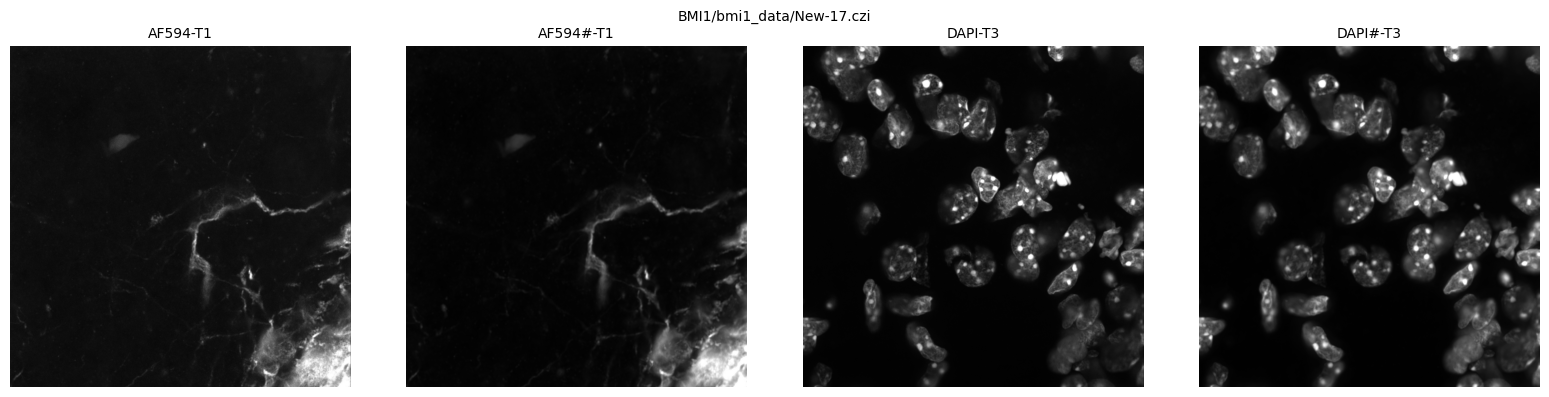

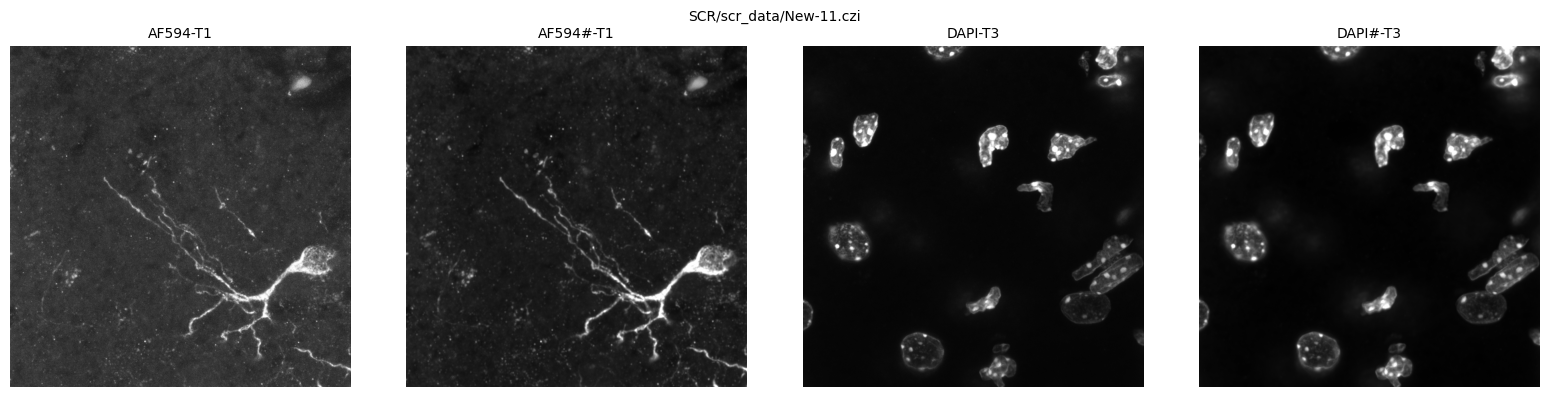

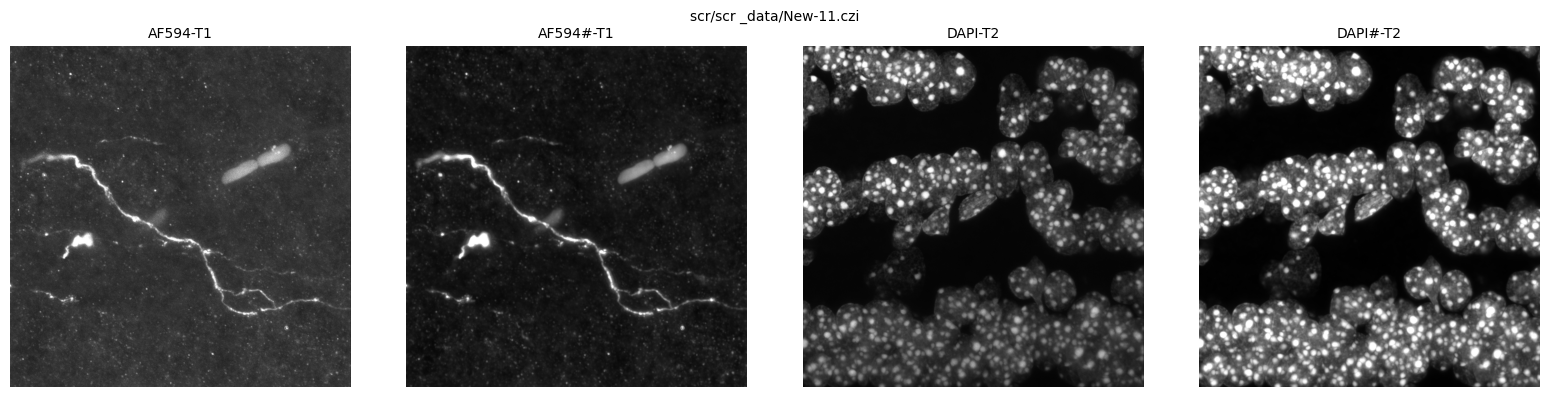

In [3]:
# one example per group, all channels
for (m, c), g in files.groupby(['mouse', 'condition']):
    mu.plot_channels(g.iloc[len(g) // 2]['path'],
                     save=os.path.join(FIG_DIR, f'channels_{m}_{c}.png'))

## Run the analysis on every image

In [4]:
images, branches, somata, _ = mu.analyze_all(files)
images.to_csv(os.path.join(CSV_DIR, 'morphology_images_czi.csv'), index=False)
branches.to_csv(os.path.join(CSV_DIR, 'morphology_branches_czi.csv'), index=False)
somata.to_csv(os.path.join(CSV_DIR, 'morphology_somata_czi.csv'), index=False)
print(f'{len(images)} images, {len(branches)} branches, {len(somata)} cell bodies')
display(mu.add_group(images).groupby('group')[['n_somata', 'ext_length_um', 'n_branches']].sum())

72 images, 10069 branches, 72 cell bodies


,n_somata,ext_length_um,n_branches
group,,,
ID06902 bmi1,41,19050.9158,2631
ID06902 scr,6,5820.1228,769
ID06914 scr,25,8435.3586,1054


## Segmentation examples

For each group: the image with the most cell bodies and the image with the most extension length.
Dots along the extensions show the measured diameter.

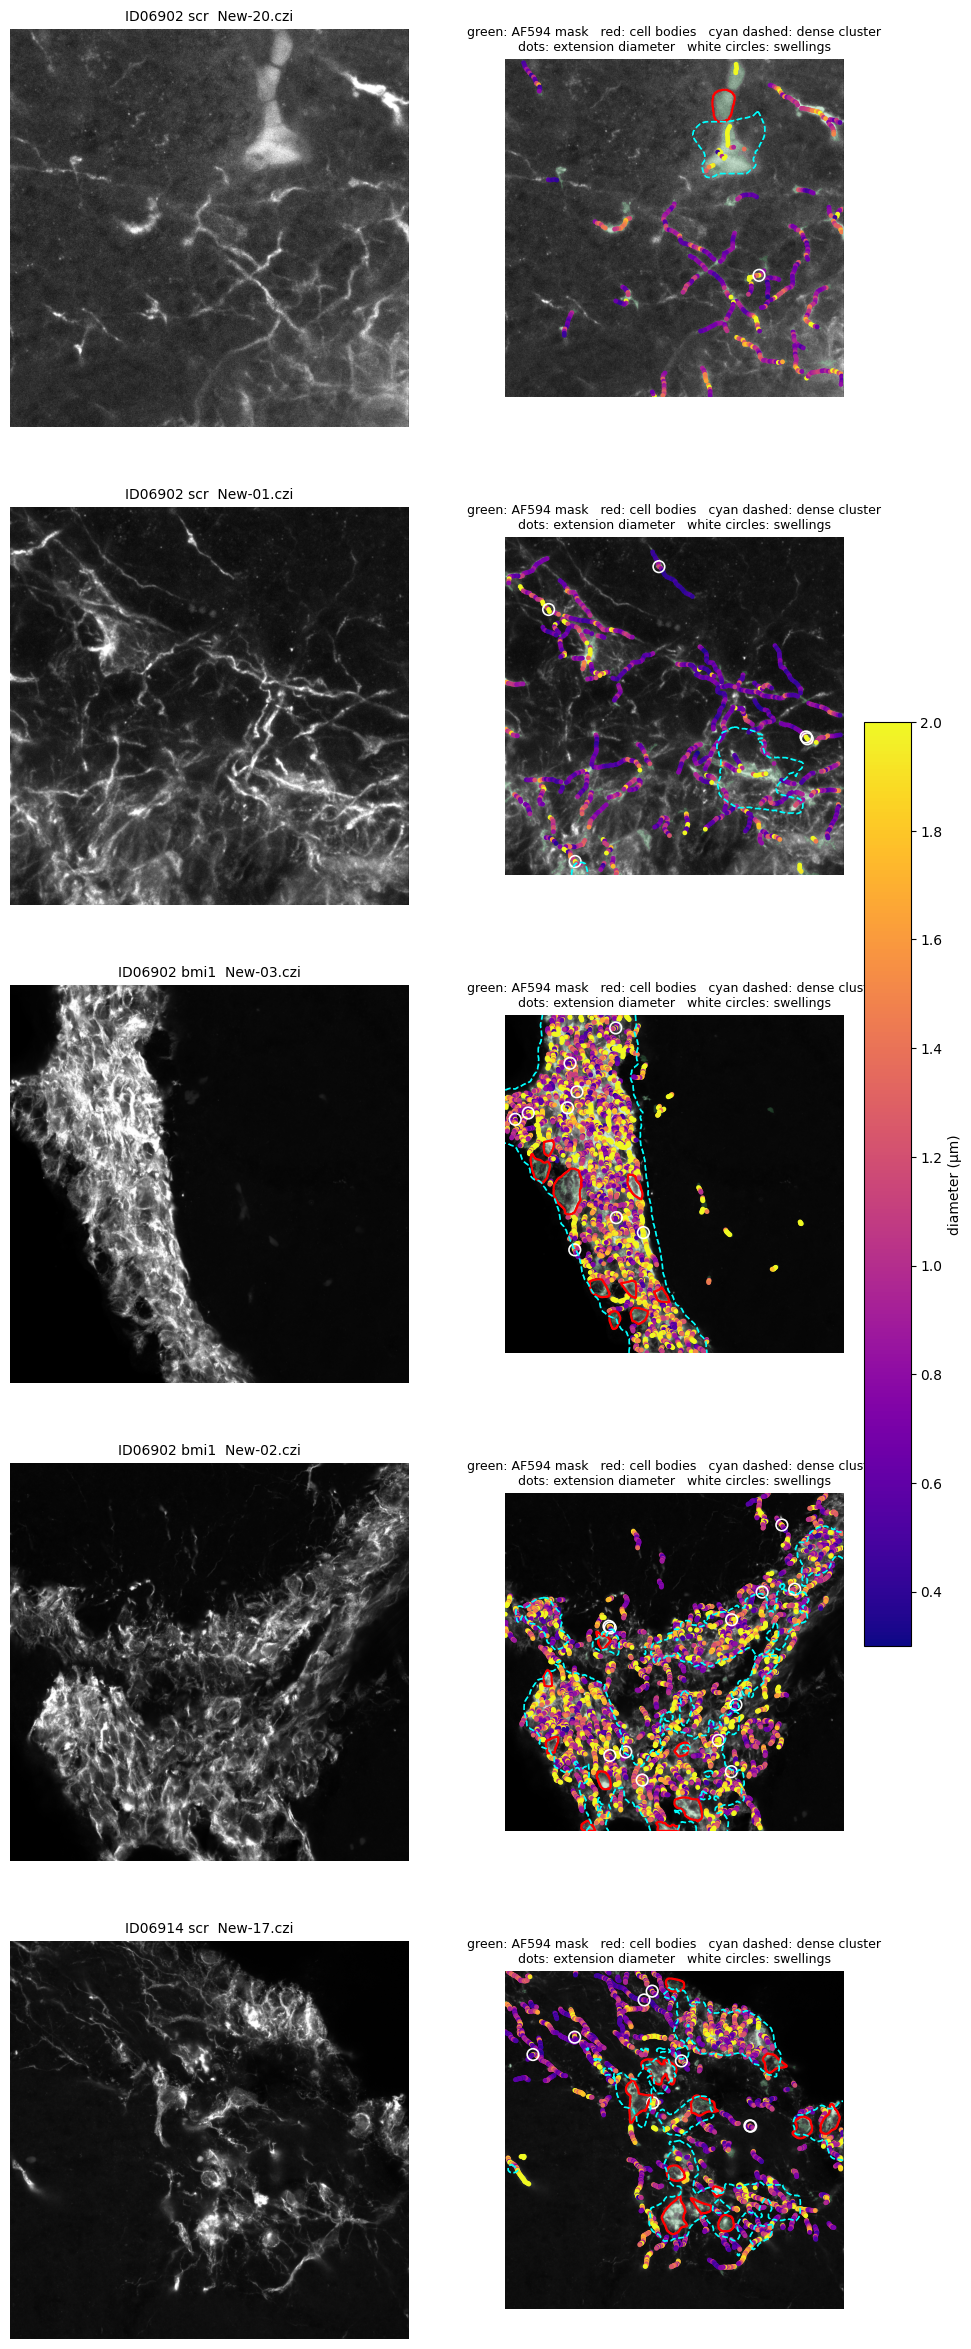

In [5]:
ex = []
for gname in mu.GROUP_ORDER:
    sub = mu.add_group(images).query('group == @gname')
    if not len(sub):
        continue
    picks = list(dict.fromkeys([sub.sort_values(['n_somata', 'ext_length_um']).iloc[-1]['filename'],
                                sub.sort_values('ext_length_um').iloc[-1]['filename']]))
    for fn in picks:
        p = files[(files['filename'] == fn) & (files['mouse'] + ' ' + files['condition'] == gname)]['path'].iloc[0]
        ex.append((f'{gname}  {fn}', mu.analyze_image(p)[3]))
mu.plot_examples(ex, save=os.path.join(FIG_DIR, 'segmentation_examples_czi.png'))

### Diameter check: FWHM widths drawn across the extensions around one cell body

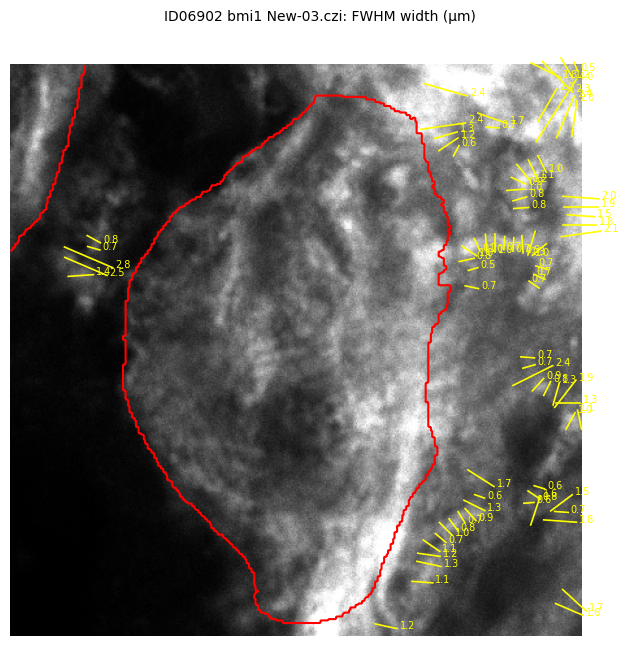

In [6]:
if len(somata):
    s = somata.sort_values(['n_primary_extensions', 'soma_area_um2']).iloc[-1]
    p = files[(files['filename'] == s['filename']) & (files['mouse'] == s['mouse'])
              & (files['condition'] == s['condition'])]['path'].iloc[0]
    a = mu.analyze_image(p)[3]
    from skimage.measure import regionprops
    cy, cx = [int(v) for v in regionprops((a['somata'] == s['soma_id']).astype(int))[0].centroid]
    mu.plot_diameter_zoom(a, (cy, cx), half=220, save=os.path.join(FIG_DIR, 'diameter_check_czi.png'),
                          title=f"{s['mouse']} {s['condition']} {s['filename']}: FWHM width (µm)")

## Extensions: one point per image

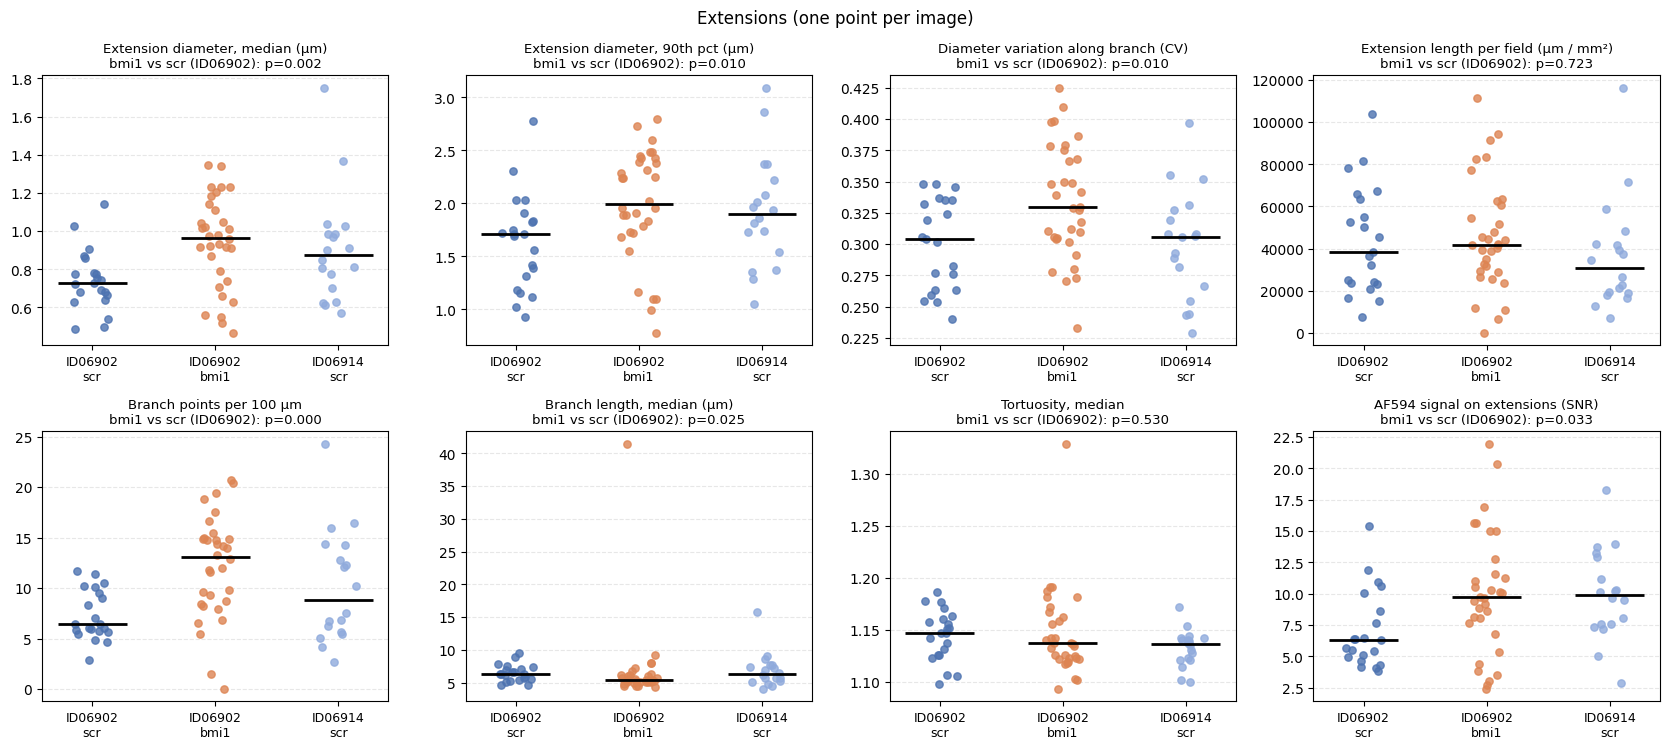

,ID06902 scr,ID06902 bmi1,ID06914 scr,n ID06902 scr,n ID06902 bmi1,n ID06914 scr,bmi1/scr (ID06902),"p bmi1 vs scr, ID06902",p bmi1 vs all scr,p scr ID06902 vs ID06914
metric,,,,,,,,,,
"Extension diameter, median (µm)",0.730,0.966,0.874,21,32,18,1.322,0.002,0.009,0.047
"Extension diameter, 90th pct (µm)",1.713,1.990,1.899,21,32,18,1.162,0.010,0.035,0.069
Diameter variation along branch (CV),0.304,0.329,0.306,21,32,18,1.082,0.010,0.004,0.989
Extension length per field (µm / mm²),38390.044,41694.394,30705.284,21,33,18,1.086,0.723,0.240,0.231
Branch points per 100 µm,6.468,13.069,8.866,21,32,18,2.021,0.000,0.001,0.118
"Branch length, median (µm)",6.336,5.435,6.309,21,32,18,0.858,0.025,0.021,1.000
"Tortuosity, median",1.147,1.137,1.136,21,32,18,0.991,0.530,0.968,0.065
AF594 signal on extensions (SNR),6.317,9.694,9.882,21,32,18,1.535,0.033,0.182,0.011


In [7]:
mu.plot_strips(images, mu.IMAGE_METRICS, save=os.path.join(FIG_DIR, 'extension_metrics_czi.png'),
               title='Extensions (one point per image)')
ext_stats = mu.stats_table(images, mu.IMAGE_METRICS)
ext_stats.to_csv(os.path.join(CSV_DIR, 'stats_extensions_czi.csv'))
ext_stats.round(3)

### Per-branch distributions (all branches ≥ 3 µm pooled per group; for the shape of the distribution, not for p-values)

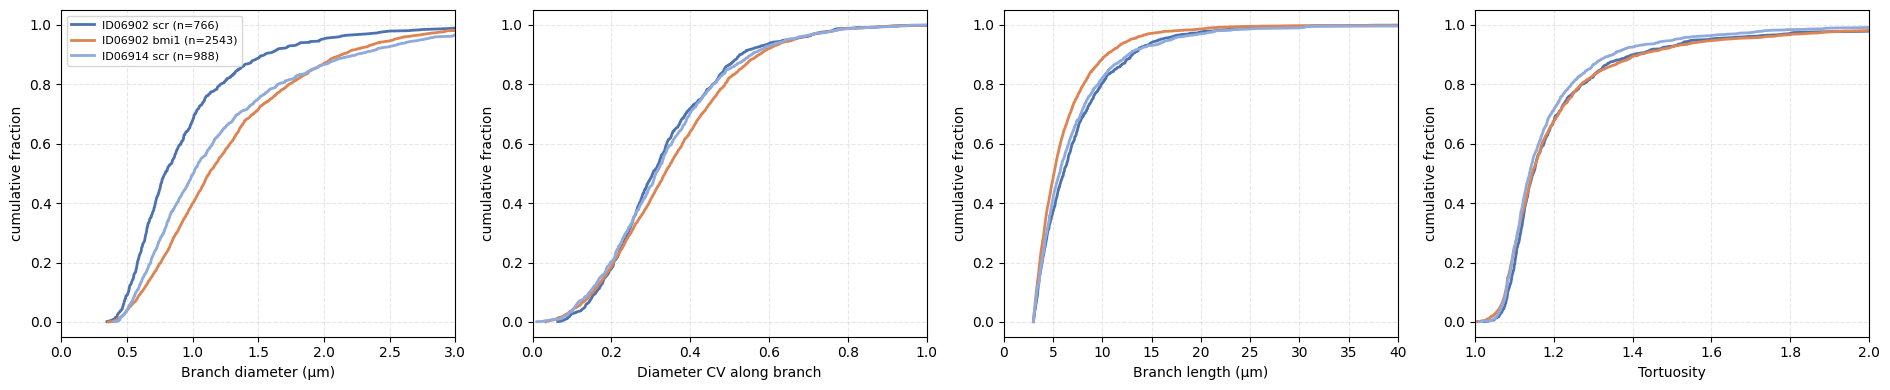

In [8]:
mu.plot_branch_distributions(branches, save=os.path.join(FIG_DIR, 'branch_distributions_czi.png'))

## Isolated extensions only (dense graft cores removed)

This is the main comparison of extension shape. The all-extension plots above mix single extensions
with the dense mesh of graft cores, which bmi1 fields contain more often.

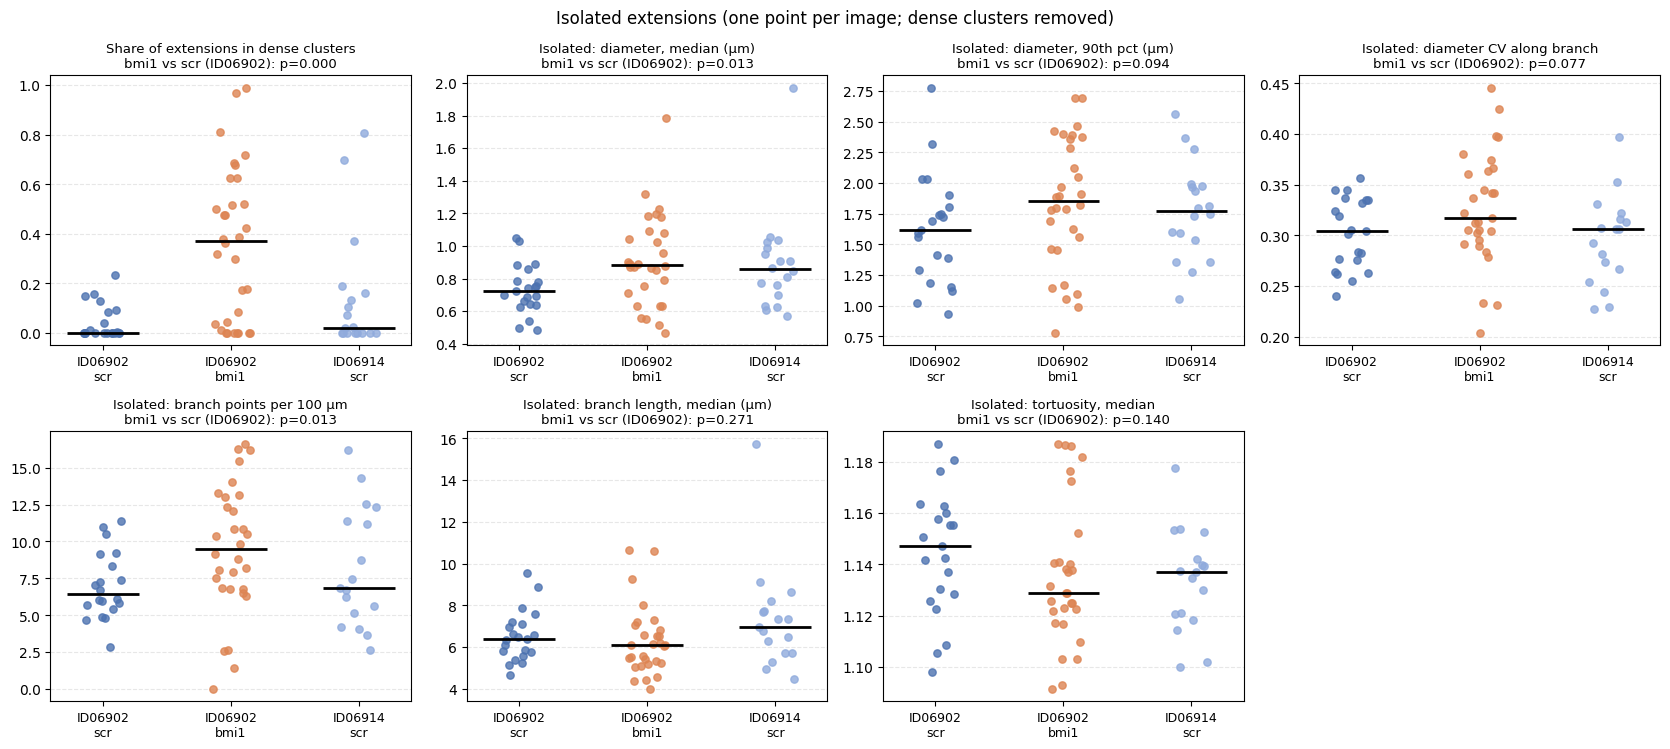

,ID06902 scr,ID06902 bmi1,ID06914 scr,n ID06902 scr,n ID06902 bmi1,n ID06914 scr,bmi1/scr (ID06902),"p bmi1 vs scr, ID06902",p bmi1 vs all scr,p scr ID06902 vs ID06914
metric,,,,,,,,,,
Share of extensions in dense clusters,0.000,0.370,0.021,21,32,18,inf,0.000,0.000,0.173
"Isolated: diameter, median (µm)",0.722,0.881,0.857,21,30,18,1.221,0.013,0.060,0.057
"Isolated: diameter, 90th pct (µm)",1.618,1.857,1.770,21,30,18,1.148,0.094,0.158,0.231
Isolated: diameter CV along branch,0.304,0.318,0.306,21,29,17,1.043,0.077,0.029,0.518
Isolated: branch points per 100 µm,6.409,9.480,6.860,20,30,17,1.479,0.013,0.024,0.532
"Isolated: branch length, median (µm)",6.386,6.097,6.981,21,29,17,0.955,0.271,0.084,0.318
"Isolated: tortuosity, median",1.147,1.129,1.137,21,29,17,0.984,0.140,0.333,0.100


In [9]:
mu.plot_strips(images, mu.ISO_METRICS, save=os.path.join(FIG_DIR, 'isolated_extension_metrics_czi.png'),
               title='Isolated extensions (one point per image; dense clusters removed)')
iso_stats = mu.stats_table(images, mu.ISO_METRICS)
iso_stats.to_csv(os.path.join(CSV_DIR, 'stats_isolated_extensions_czi.csv'))
iso_stats.round(3)

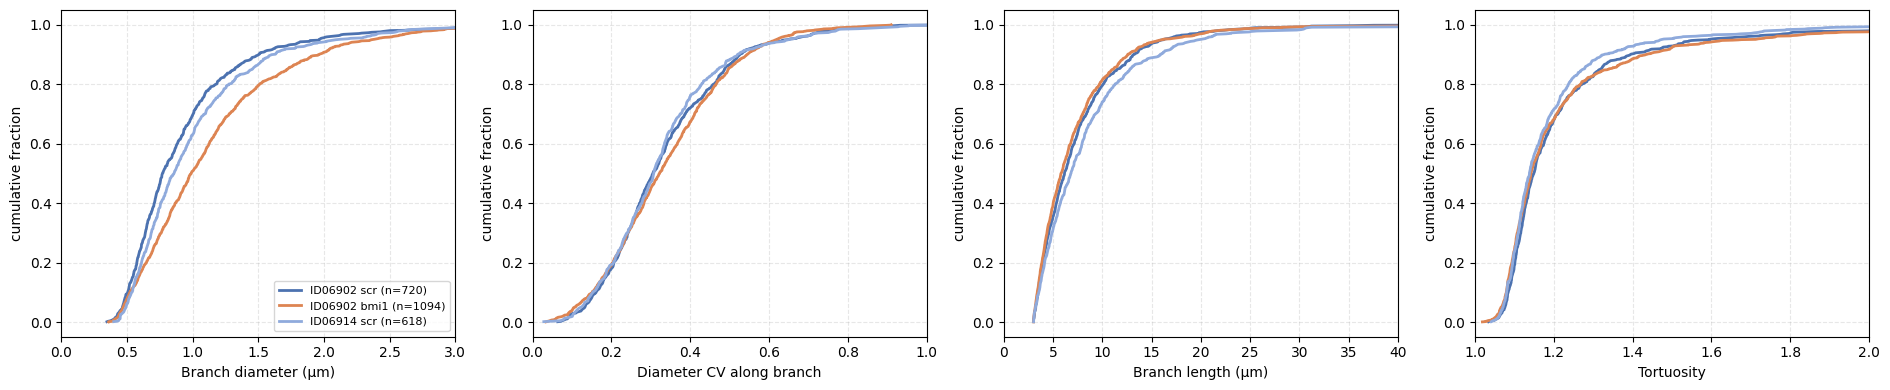

In [10]:
mu.plot_branch_distributions(branches, isolated_only=True,
                             save=os.path.join(FIG_DIR, 'branch_distributions_isolated_czi.png'))

## Swellings (Flamier et al. 2018, Fig 3F)

The paper counted the % of axons with at least one swelling (higher in shBMI1 neurons). Here the unit
is a skeleton branch, the closest equivalent; the per-length rate does not depend on that choice.
The isolated-only values are the main comparison.

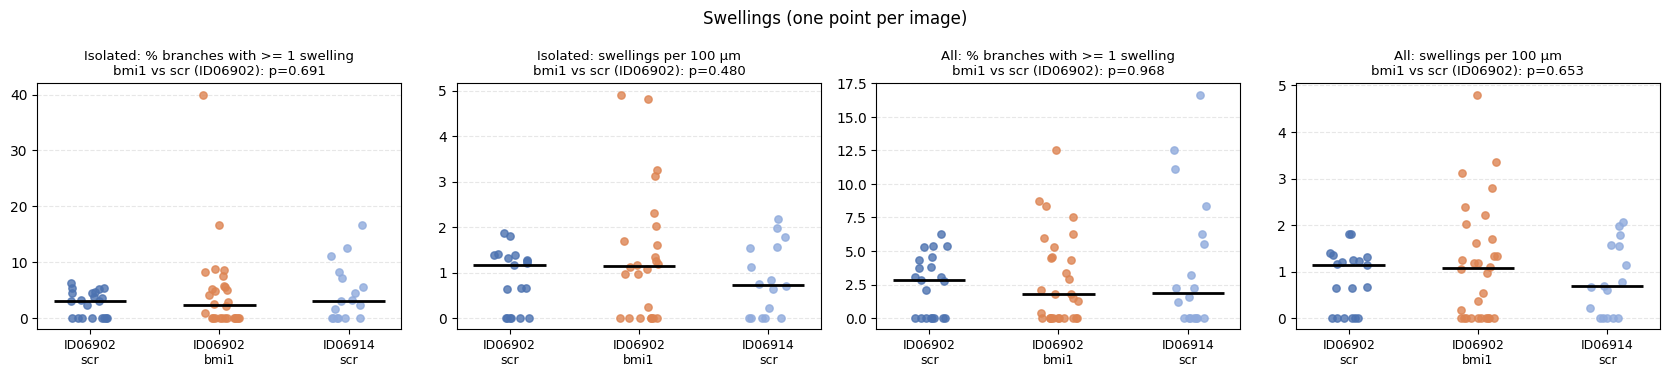

,ID06902 scr,ID06902 bmi1,ID06914 scr,n ID06902 scr,n ID06902 bmi1,n ID06914 scr,bmi1/scr (ID06902),"p bmi1 vs scr, ID06902",p bmi1 vs all scr,p scr ID06902 vs ID06914
metric,,,,,,,,,,
Isolated: % branches with >= 1 swelling,3.077,2.279,3.093,21,28,17,0.741,0.691,0.995,0.479
Isolated: swellings per 100 µm,1.160,1.153,0.727,19,24,16,0.994,0.480,0.302,1.000
All: % branches with >= 1 swelling,2.857,1.782,1.902,21,29,18,0.624,0.968,0.878,0.772
All: swellings per 100 µm,1.148,1.080,0.685,19,30,16,0.941,0.653,0.542,1.000


In [11]:
mu.plot_strips(images, mu.SWELL_METRICS, ncols=4, save=os.path.join(FIG_DIR, 'swelling_metrics_czi.png'),
               title='Swellings (one point per image)')
swell_stats = mu.stats_table(images, mu.SWELL_METRICS)
swell_stats.to_csv(os.path.join(CSV_DIR, 'stats_swellings_czi.csv'))
swell_stats.round(3)

### Swelling check: widths drawn across the extension, red = detected swelling (one example per group)

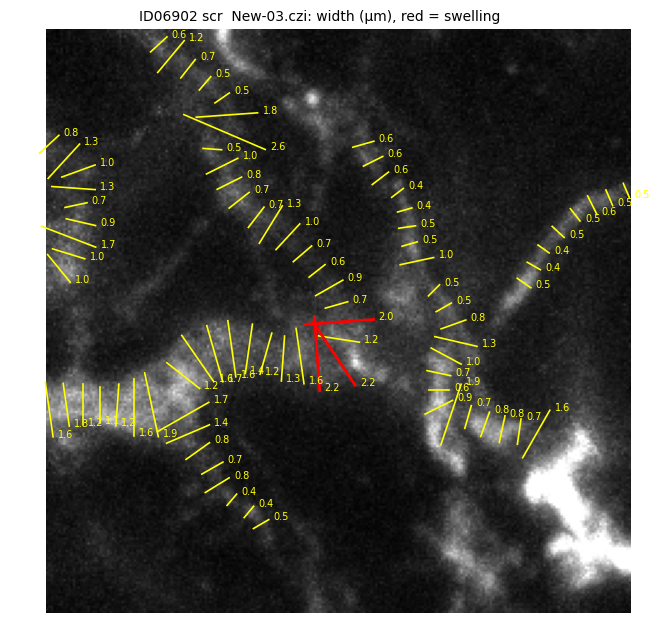

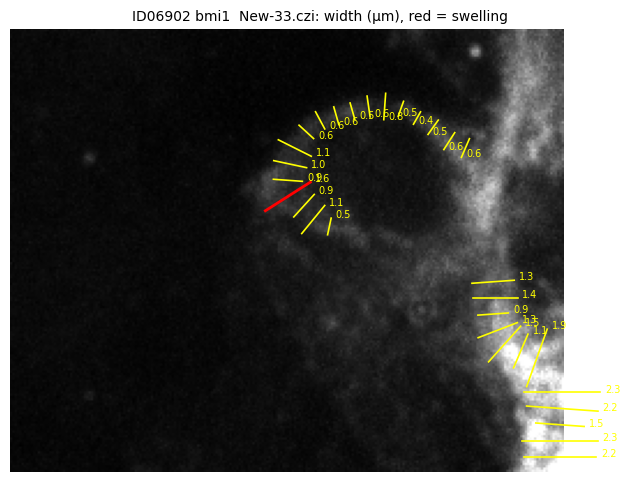

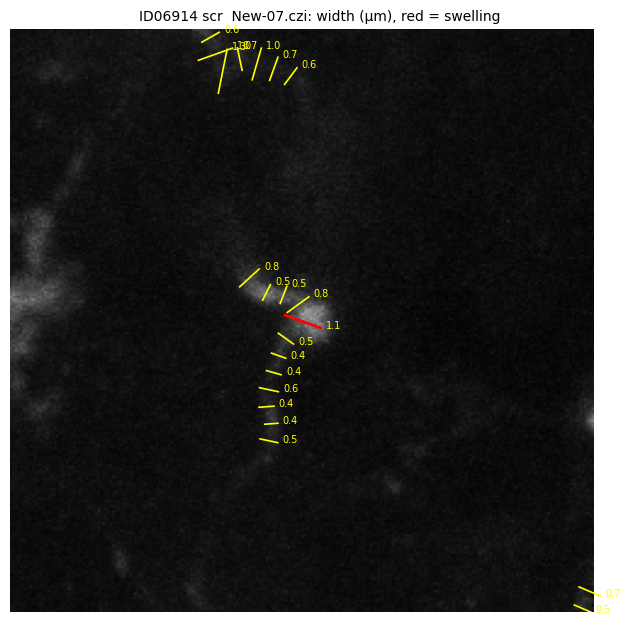

In [12]:
sw_br = mu.add_group(branches).query('n_swellings > 0 and local_density < @mu.DENSE_THR')
for gname in mu.GROUP_ORDER:
    g = sw_br[sw_br['group'] == gname]
    if not len(g):
        continue
    fn = mu.add_group(images).query('group == @gname').set_index('filename').loc[g['filename'].unique()] \
            ['iso_swellings_per_100um'].idxmax()
    p = files[(files['filename'] == fn) & (files['mouse'] + ' ' + files['condition'] == gname)]['path'].iloc[0]
    a = mu.analyze_image(p)[3]
    S = a['diam_samples']; sw = S[(S[:, 6] > 0) & (S[:, 5] < mu.DENSE_THR)]
    mu.plot_diameter_zoom(a, (int(sw[0, 0]), int(sw[0, 1])), half=120,
                          save=os.path.join(FIG_DIR, f'swelling_check_{gname.replace(" ", "_")}_czi.png'),
                          title=f'{gname}  {fn}: width (µm), red = swelling')

## Isolated neurons: dendrite length and area per neuron (Flamier et al. 2018, Fig 2B)

One point per isolated neuron, meaning a cell body outside dense clusters. Read these numbers with
the following in mind:
- **Lower bounds:** the images are 2D projections of thick tissue, and dendrites leave the focal
  volume and the field of view. Neurons whose dendrites reach the image edge are flagged (`touches_border`).
- **Crossings:** a fibre from another cell that crosses a dendrite can be assigned to the neuron.
- **Few neurons:** isolated bmi1 neurons are rare, as Iman noted.

,n_neurons,touching_edge
group,,
ID06902 scr,5,0
ID06902 bmi1,6,1
ID06914 scr,7,2


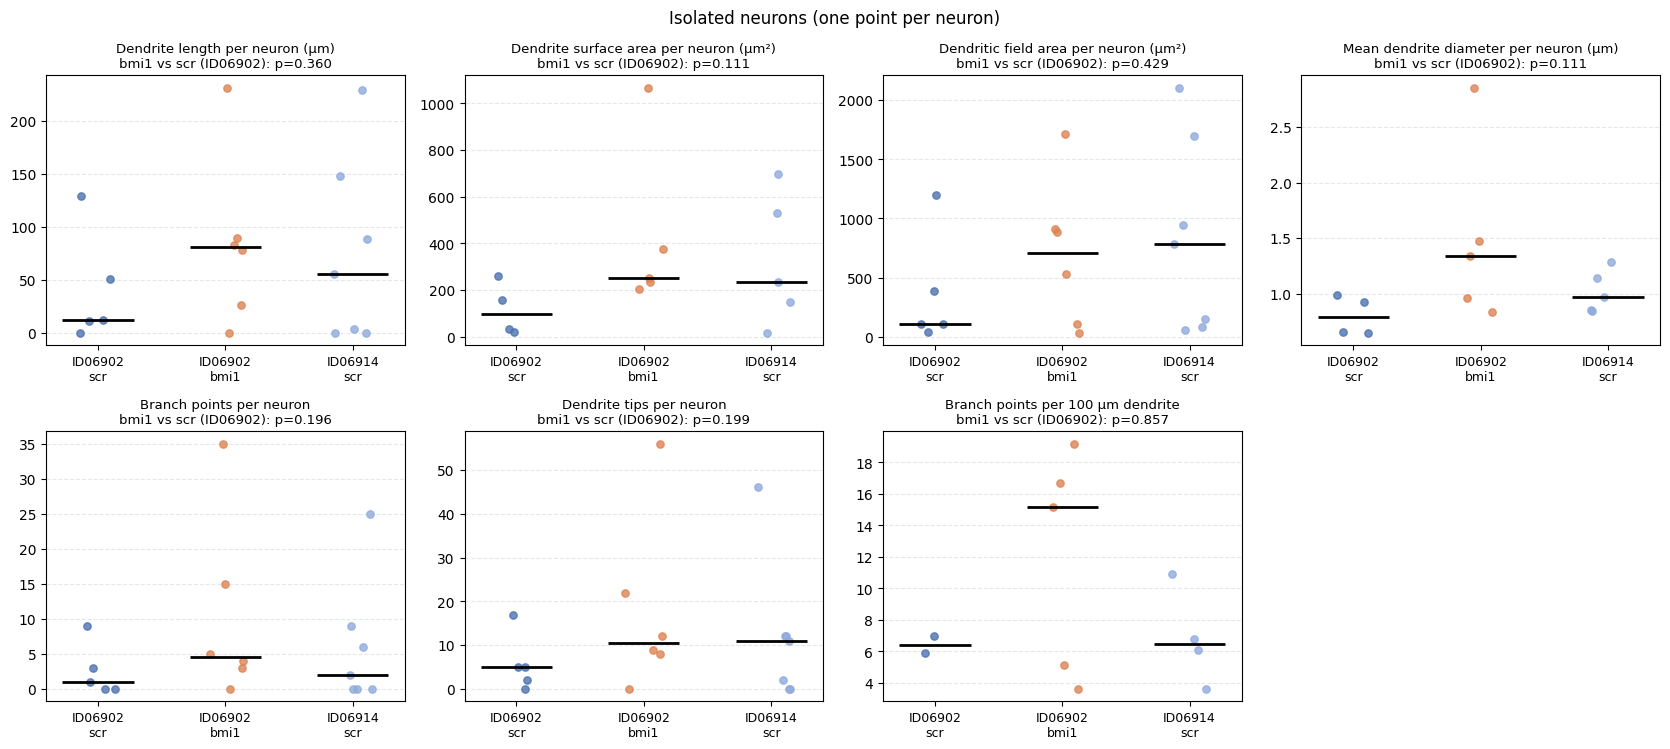

,ID06902 scr,ID06902 bmi1,ID06914 scr,n ID06902 scr,n ID06902 bmi1,n ID06914 scr,bmi1/scr (ID06902),"p bmi1 vs scr, ID06902",p bmi1 vs all scr,p scr ID06902 vs ID06914
metric,,,,,,,,,,
Dendrite length per neuron (µm),12.214,80.837,55.280,5,6,7,6.618,0.360,0.451,0.744
Dendrite surface area per neuron (µm²),96.916,250.190,234.746,4,5,5,2.582,0.111,0.240,0.556
Dendritic field area per neuron (µm²),106.461,708.756,786.422,5,6,7,6.657,0.429,0.820,0.432
Mean dendrite diameter per neuron (µm),0.789,1.335,0.972,4,5,5,1.693,0.111,0.147,0.286
Branch points per neuron,1.000,4.500,2.000,5,6,7,4.500,0.196,0.233,0.800
Dendrite tips per neuron,5.000,10.500,11.000,5,6,7,2.100,0.199,0.299,0.805
Branch points per 100 µm dendrite,6.420,15.151,6.432,2,5,4,2.360,0.857,0.537,1.000


In [13]:
iso_neurons = somata[~somata['in_dense_cluster']].copy()
display(mu.add_group(iso_neurons).groupby('group').agg(n_neurons=('soma_id', 'size'),
        touching_edge=('touches_border', 'sum')).reindex(mu.GROUP_ORDER))
mu.plot_strips(iso_neurons, mu.NEURON_METRICS, ncols=4, save=os.path.join(FIG_DIR, 'isolated_neuron_metrics_czi.png'),
               title='Isolated neurons (one point per neuron)')
neuron_stats = mu.stats_table(iso_neurons, mu.NEURON_METRICS)
neuron_stats.to_csv(os.path.join(CSV_DIR, 'stats_isolated_neurons_czi.csv'))
neuron_stats.round(3)

### Same, only neurons whose dendrites stay inside the image

In [14]:
inside = iso_neurons[~iso_neurons['touches_border'].astype(bool)]
neuron_stats_in = mu.stats_table(inside, mu.NEURON_METRICS)
neuron_stats_in.to_csv(os.path.join(CSV_DIR, 'stats_isolated_neurons_inside_czi.csv'))
neuron_stats_in.round(3)

,ID06902 scr,ID06902 bmi1,ID06914 scr,n ID06902 scr,n ID06902 bmi1,n ID06914 scr,bmi1/scr (ID06902),"p bmi1 vs scr, ID06902",p bmi1 vs all scr,p scr ID06902 vs ID06914
metric,,,,,,,,,,
Dendrite length per neuron (µm),12.214,83.308,4.024,5,5,5,6.821,0.346,0.323,0.833
Dendrite surface area per neuron (µm²),96.916,313.286,234.746,4,4,3,3.233,0.114,0.164,0.857
Dendritic field area per neuron (µm²),106.461,884.141,150.971,5,5,5,8.305,0.421,0.371,0.841
Mean dendrite diameter per neuron (µm),0.789,1.146,1.141,4,4,3,1.452,0.200,0.315,0.229
Branch points per neuron,1.000,4.000,0.000,5,5,5,4.000,0.243,0.183,0.911
Dendrite tips per neuron,5.000,12.000,2.000,5,5,5,2.400,0.248,0.154,0.750
Branch points per 100 µm dendrite,6.420,10.128,6.432,2,4,2,1.578,1.000,1.000,1.000


### Every isolated neuron and the dendrites assigned to it (visual check of the isolation rule)

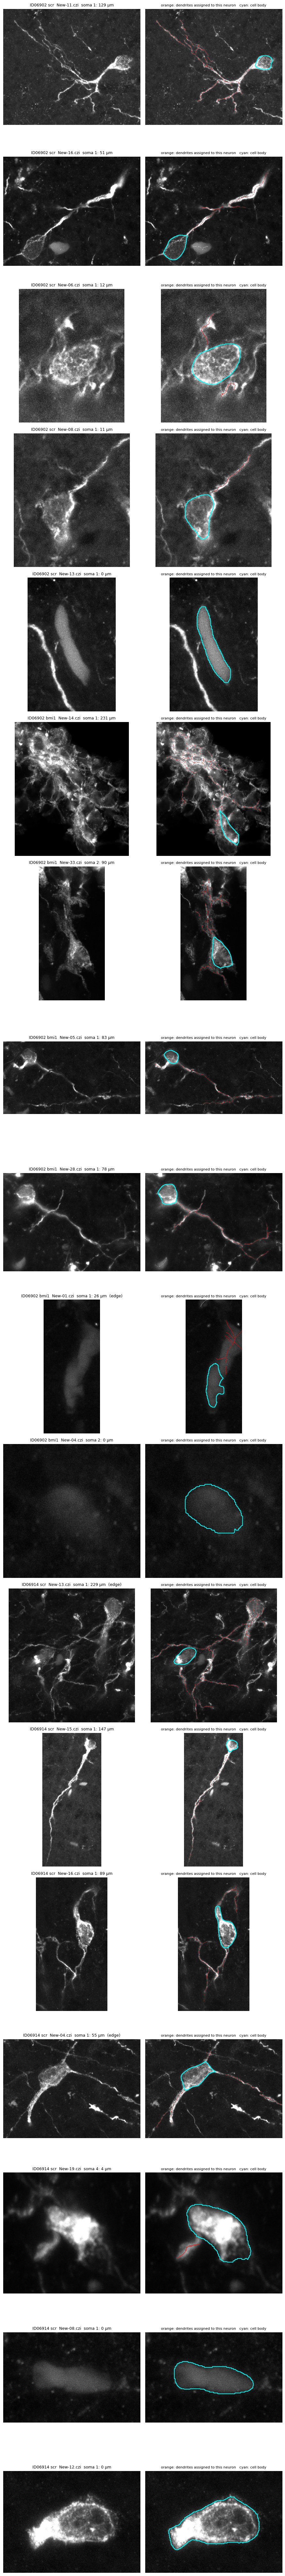

In [15]:
items = []
for gname in mu.GROUP_ORDER:
    g = mu.add_group(iso_neurons).query('group == @gname').sort_values('dend_length_um', ascending=False)
    for _, n in g.iterrows():
        p = files[(files['filename'] == n['filename']) & (files['mouse'] == n['mouse'])
                  & (files['condition'] == n['condition'])]['path'].iloc[0]
        a = mu.analyze_image(p)[3]
        items.append((f"{gname}  {n['filename']}  soma {n['soma_id']}: {n['dend_length_um']:.0f} µm"
                      + ('  (edge)' if n['touches_border'] else ''), a, n['soma_id']))
mu.plot_neuron_gallery(items, save=os.path.join(FIG_DIR, 'isolated_neuron_gallery_czi.png'))

## Cell bodies: one point per detected soma

,n somata
group,
ID06902 scr,6
ID06902 bmi1,41
ID06914 scr,25


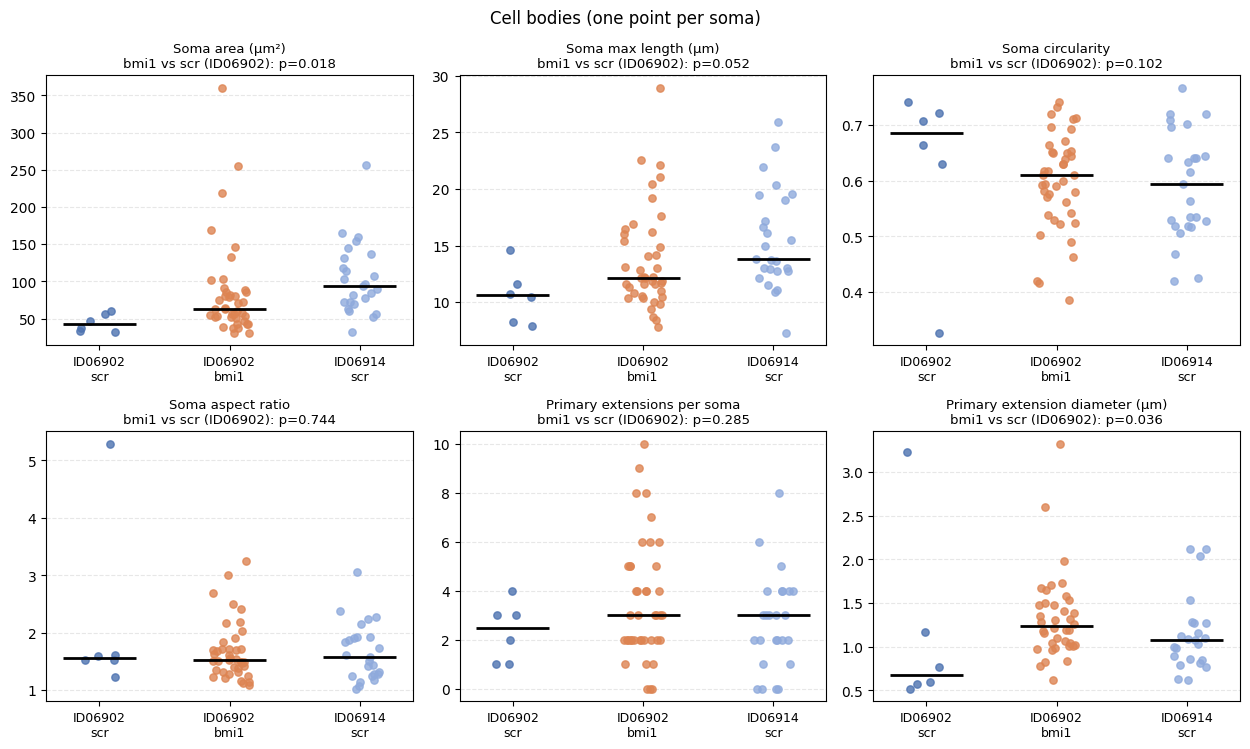

,ID06902 scr,ID06902 bmi1,ID06914 scr,n ID06902 scr,n ID06902 bmi1,n ID06914 scr,bmi1/scr (ID06902),"p bmi1 vs scr, ID06902",p bmi1 vs all scr,p scr ID06902 vs ID06914
metric,,,,,,,,,,
Soma area (µm²),42.474,63.351,94.070,6,41,25,1.492,0.018,0.145,0.000
Soma max length (µm),10.593,12.152,13.822,6,41,25,1.147,0.052,0.265,0.005
Soma circularity,0.686,0.609,0.594,6,41,25,0.888,0.102,0.820,0.190
Soma aspect ratio,1.563,1.523,1.584,6,41,25,0.974,0.744,0.946,0.865
Primary extensions per soma,2.500,3.000,3.000,6,41,25,1.200,0.285,0.175,0.722
Primary extension diameter (µm),0.679,1.236,1.079,6,38,23,1.820,0.036,0.015,0.142


,in dense cluster,all somata
group,,
ID06902 scr,1,6
ID06902 bmi1,35,41
ID06914 scr,18,25


In [16]:
if len(somata):
    display(mu.add_group(somata)['group'].value_counts().reindex(mu.GROUP_ORDER).rename('n somata').to_frame())
    mu.plot_strips(somata, mu.SOMA_METRICS, ncols=3, save=os.path.join(FIG_DIR, 'soma_metrics_czi.png'),
                   title='Cell bodies (one point per soma)')
    soma_stats = mu.stats_table(somata, mu.SOMA_METRICS)
    soma_stats.to_csv(os.path.join(CSV_DIR, 'stats_somata_czi.csv'))
    display(soma_stats.round(3))
    display(mu.add_group(somata).groupby('group')['in_dense_cluster'].agg(['sum', 'size'])
            .rename(columns={'sum': 'in dense cluster', 'size': 'all somata'}).reindex(mu.GROUP_ORDER))

## Findings (regular CZI, 72 images)

**1. bmi1 neurons sit in dense clusters; scr neurons are isolated. This is the clearest difference.**
In bmi1, 37% of the extension length lies in dense graft cores (median per image). In scr it is 0% in
ID06902 and 2% in ID06914 (p < 0.001 against both). 33 of 41 bmi1 cell bodies sit in a dense cluster;
none of the 6 scr cell bodies in the same mouse do.

**2. Isolated bmi1 extensions branch more.** On isolated extensions only, bmi1 has 9.5 branch points
per 100 µm, against 6.4 for scr in the same mouse (p = 0.013) and 6.9 in the second scr mouse
(bmi1 vs all scr p = 0.024). Branch length and tortuosity do not differ.

**3. Extension diameter: bmi1 is thicker than scr in the same mouse, but not than the second scr mouse.**
Isolated extensions: bmi1 0.88 µm, scr ID06902 0.72 µm (p = 0.013), scr ID06914 0.86 µm. Primary
extension diameter near the soma shows the same pattern (bmi1 1.24, scr 0.68 / 1.08 µm). Because the
second scr mouse is as thick as bmi1, this difference cannot be credited to bmi1.

**4. Soma shape: no reliable difference.** bmi1 somata are larger than scr in ID06902 (63 vs 42 µm²,
p = 0.018), but only 6 scr somata were found there, and scr ID06914 somata are larger still (94 µm²).
Circularity, aspect ratio and number of primary extensions do not differ.

Without the dense-cluster split, bmi1 would look 2x more branched and 1.3x thicker. Most of that comes
from the dense mesh.

**5. Swellings (paper Fig 3F): no difference.** Swellings are rare in all groups. On isolated
extensions, 2.3% of bmi1 branches have at least one, against 3.1% for scr in both mice (p = 0.69).
Per length: 1.15 per 100 µm (bmi1) vs 1.16 (scr ID06902) and 0.73 (scr ID06914), p = 0.48. Diameter
CV along branches, a continuous measure of beading, does not differ either (p = 0.077). The detector is
strict, and a visual check shows some detections at bends or branch points, so treat the counts as rough.

**Limits.**
- bmi1 comes from one mouse (ID06902). A bmi1 vs scr difference cannot be fully separated from a difference between mice; the two scr mice already differ in diameter and soma size.
- Images are fields picked by the experimenter, not random samples. Statistics are per image (or per soma), not per animal.
- Cell bodies are found by Cellpose-SAM with filters. It misses some and splits a few large somata, so treat the soma numbers as rough.